<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/deep-learning/07_pytorch_experiment_tracking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### What is experiment tracking?
* ANS - Machine learning and deep learning are very experimental.

1. You have to put on your artist's beret/chef's hat to cook up lots of different models.

2. And you have to put on your scientist's coat to track the results of various combinations of data, model architectures and training regimes.

3. That's where experiment tracking comes in.

4. If you're running lots of different experiments, experiment tracking helps you figure out what works and what doesn'

#### Why track experiments?
* If you're only running a handful of models (like we've done so far), it might be okay just to track their results in print outs and a few dictionaries.

* However, as the number of experiments you run starts to increase, this naive way of tracking could get out of hand.

* So if you're following the machine learning practitioner's motto of experiment, experiment, experiment!, you'll want a way to track them

there are as many different ways to track machine learning experiments as there are experiments to run.

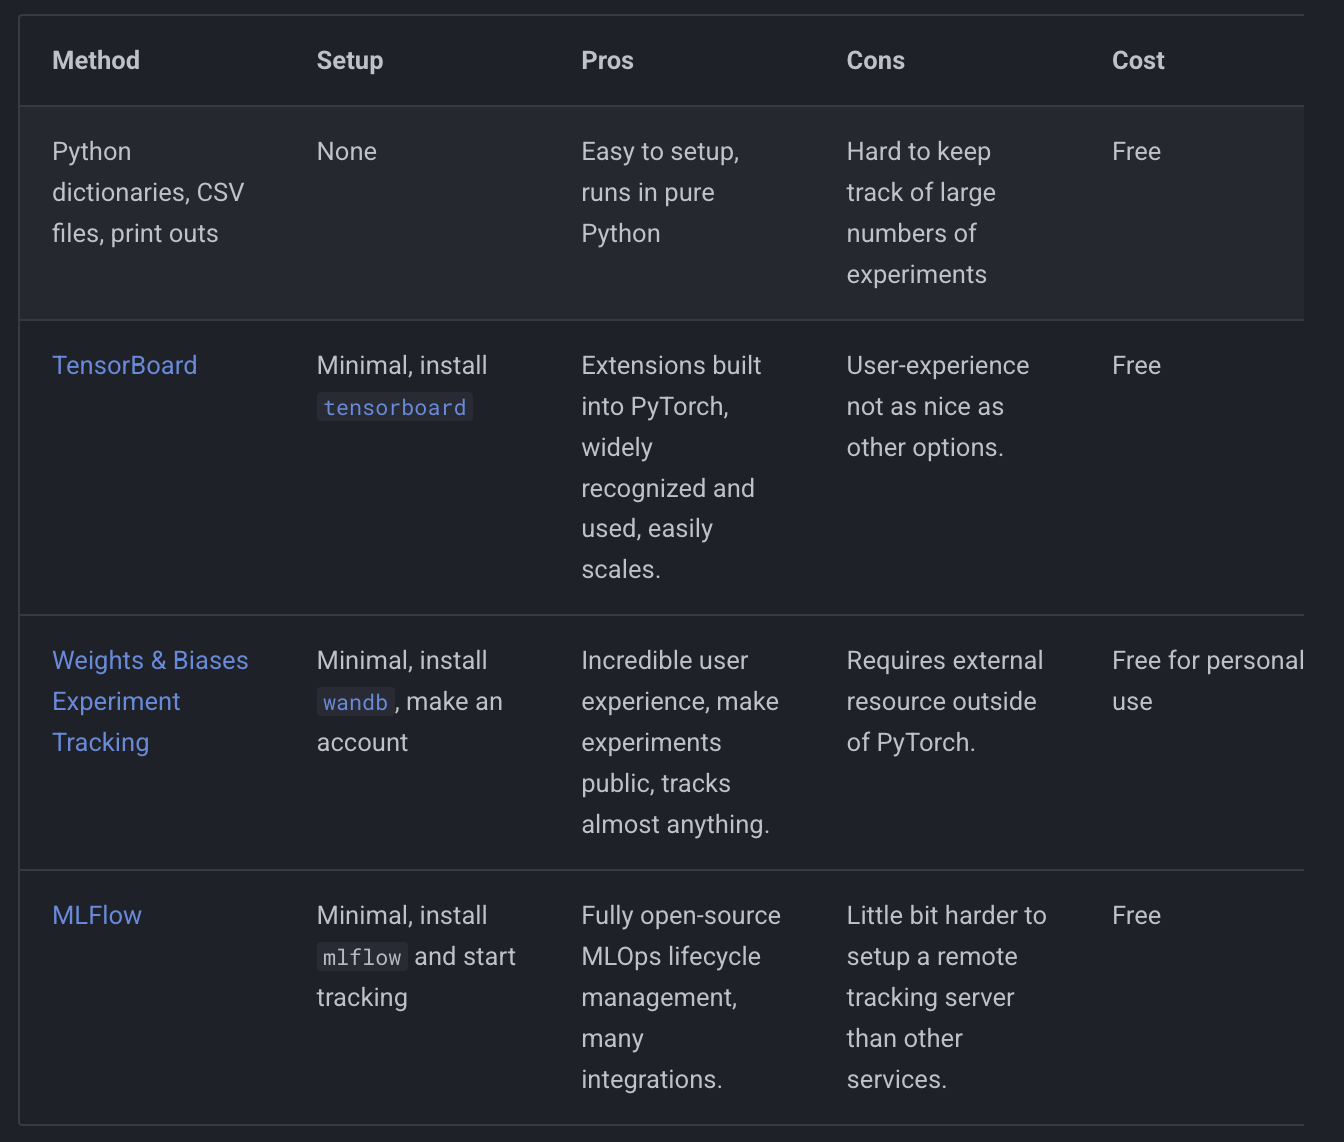

# 0. getting setup

:- To save us writing extra code, we're going to be leveraging some of the Python scripts (such as data_setup.py and engine.py) we created in section, 05. PyTorch Going Modular.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive')

from going_modular.going_modular import data_setup, engine

Mounted at /content/drive


In [ ]:
import torch
import torchvision
from torchvision import transforms
from torch import nn
import matplotlib.pyplot as plt

torch.__version__
torchvision.__version__



'0.26.0+cpu'

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
def set_seeds(seed: int = 42):
  """Sets random sets for torch operations.

    Args:
        seed (int, optional): Random seed to set. Defaults to 42.
  """
  # set the seed for general torch operations
  torch.manual_seed(seed)
  # set the seed for Cuda torch operatiosn (ones that happen on the GPU)
  torch.cuda.manual_seed(42)


# 1. Get data
As always, before we can run machine learning experiments, we'll need a dataset.

We're going to continue trying to improve upon the results we've been getting on FoodVision Mini.

In the previous section, 06. PyTorch Transfer Learning, we saw how powerful using a pretrained model and transfer learning could be when classifying images of pizza, steak and sushi.

So how about we run some experiments and try to further improve our results?

To do so, we'll use similar code to the previous section to download the pizza_steak_sushi.zip (if the data doesn't already exist) except this time it's been functionalised.

This will allow us to use it again later.

In [ ]:
import os
import zipfile

from pathlib import Path

import requests

def download_data(source: str,
                  destination: str,
                  remove_source: bool = True) -> Path:
    """Downloads a zipped dataset from source and unzips to destination.

    Args:
        source (str): A link to a zipped file containing data.
        destination (str): A target directory to unzip data to.
        remove_source (bool): Whether to remove the source after downloading and extracting.

    Returns:
        pathlib.Path to downloaded data.

    Example usage:
        download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                      destination="pizza_steak_sushi")
    """
    # Setup path to data folder
    data_path = Path("data/")
    image_path = data_path / destination

    # If the image folder doesn't exist, download it and prepare it...
    if image_path.is_dir():
        print(f"[INFO] {image_path} directory exists, skipping download.")
    else:
        print(f"[INFO] Did not find {image_path} directory, creating one...")
        image_path.mkdir(parents=True, exist_ok=True)

        # Download pizza, steak, sushi data
        target_file = Path(source).name
        with open(data_path / target_file, "wb") as f:
            request = requests.get(source)
            print(f"[INFO] Downloading {target_file} from {source}...")
            f.write(request.content)

        # Unzip pizza, steak, sushi data
        with zipfile.ZipFile(data_path / target_file, "r") as zip_ref:
            print(f"[INFO] Unzipping {target_file} data...")
            zip_ref.extractall(image_path)

        # Remove .zip file
        if remove_source:
            os.remove(data_path / target_file)

    return image_path

image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] Did not find data/pizza_steak_sushi directory, creating one...
[INFO] Downloading pizza_steak_sushi.zip from https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip...
[INFO] Unzipping pizza_steak_sushi.zip data...


PosixPath('data/pizza_steak_sushi')

# 2. Create Datasets and DataLoaders

:- We can do so using the create_dataloaders() function we created in 05. PyTorch Going Modular part 2.

* To transform our images into tensors, we can use:

1. Manually created transforms using torchvision.transforms.
Automatically created transforms using torchvision.models.MODEL_NAME.MODEL_WEIGHTS.DEFAULT.transforms().

2. Where MODEL_NAME is a specific torchvision.models architecture, MODEL_WEIGHTS is a specific set of pretrained weights and DEFAULT means the "best available weights".

### 2.1 Create DataLoaders using manually created transforms

Note :-

* Mean = the average pixel brightness across a channel (R, G, or B).

* Std = how spread out those pixel values are — high std means lots of variation (dark and bright mixed), low std means values are close together.

[Normalization does: (pixel - mean) / std]

Simplest way to think about it: it re-centers your pixel values around 0 and scales them so most values land between -1 and 1, instead of 0 to 1. This makes it easier and faster for the neural network to learn patterns, and matches the exact scaling the pretrained model was trained on.

In [ ]:
# setup directories
train_dir = image_path / "train"
test_dir = image_path / "test"

# setup ImageNet normalization levels (turns all images into similar distribution as ImageNet)
normalize = transforms.Normalize(mean = [0.485 , 0.456, 0.406],
                                 std = [0.229 , 0.224 , 0.225])

# create transform pipeline manually
manual_transforms = transforms.Compose([
    transforms.Resize (size = (224, 224)),
    transforms.ToTensor(),
    normalize
])
print(f"manually created transforms : {manual_transforms} ")

# create data loaders
print(f"manually created transforms : {manual_transforms}")

# create data loaders
train_dataloader , test_dataloader , class_names = data_setup.create_dataloaders(
    train_dir = train_dir ,
    test_dir = test_dir,
    transform = manual_transforms ,
    batch_size =32
)

train_dataloader , test_dataloader, class_names

manually created transforms : Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
) 
manually created transforms : Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


(<torch.utils.data.dataloader.DataLoader at 0x7a00486dde20>,
 ['pizza', 'steak', 'sushi'])

### 2.2 Create DataLoaders using automatically created transforms
Data transformed and DataLoaders created!

Let's now see what the same transformation pipeline looks like but this time by using automatic transforms.

We can do this by first instantiating a set of pretrained weights (for example weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT) we'd like to use and calling the transforms() method on it.

In [ ]:
# setup dir
train_dir = image_path / "train"
test_dir = image_path / "test"

# Setup pretrained weights (plenty of these available in torchvision.models)
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT

# get transforms from weights (these are the transforms that were used to obtain the weights )
automatic_transforms = weights.transforms()
print(f"automatically created transforms : {automatic_transforms}")

# create data loaders

train_dataloader, test_dataloader ,class_names = data_setup.create_dataloaders(
    train_dir = train_dir ,
    test_dir = test_dir ,
    transform = automatic_transforms, # use automatic created transforms
    batch_size = 32
)


train_dataloader , test_dataloader ,class_names

automatically created transforms : ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)


(<torch.utils.data.dataloader.DataLoader at 0x7a0048147d10>,
 ['pizza', 'steak', 'sushi'])

# 3. Getting a pretrained model, freezing the base layers and changing the classifier head

Before we run and track multiple modelling experiments, let's see what it's like to run and track a single one.

And since our data is ready, the next thing we'll need is a model.

Let's download the pretrained weights for a torchvision.models.efficientnet_b0() model and prepare it for use with our own data

In [ ]:
# Note: This is how a pretrained model would be created in torchvision > 0.13, it will be deprecated in future versions.
# model = torchvision.models.efficientnet_b0(pretrained=True).to(device) # OLD

# Download the pretrained weights for EfficientNet_B0
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT

# setup the model with the pretrained weights and send it to the target device
model = torchvision.models.efficientnet_b0(weights = weights).to(device)

model

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 69.1MB/s]


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

Now we've got a pretrained model let's turn it into a feature extractor model.

In essence, we'll freeze the base layers of the model (we'll use these to extract features from our input images) and we'll change the classifier head (output layer) to suit the number of classes we're working with (we've got 3 classes: pizza, steak, sushi).

In [ ]:
# freeze all base layers by setting requires_grad attribute to False

for param in model.features.parameters():
  param.requires_grad = False

# Since we're creating a new layer with random weights (torch.nn.Linear),
# let's set the seeds

set_seeds()

# update the classifier head to suit our problem
model.classifier = torch.nn.Sequential(
    nn.Dropout(p = 0.2 ,inplace = True ),
    nn.Linear(in_features = 1280 ,
              out_features = len(class_names),
              bias = True).to(device)
)


In [ ]:
try:
    from torchinfo import summary
except ModuleNotFoundError:
    !pip install -q torchinfo
    from torchinfo import summary

summary(model=model,
        input_size=(32, 3, 224, 224),
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

# 4. Train model and track results
Model ready to go!

Let's get ready to train it by creating a loss function and an optimizer.

Since we're working with multiple classes, we'll use torch.nn.CrossEntropyLoss() as the loss function.

And we'll stick with torch.optim.Adam() with learning rate of 0.001 for the optimizer

In [ ]:
# define loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params = model.parameters(),
                             lr = 0.001)

1. SGD (Stochastic Gradient Descent)

* Simple: takes a fixed-size step in the direction that reduces loss
* You have to manually tune the learning rate carefully — too big and it overshoots, too small and it's painfully slow
* Treats all parameters the same way

2. Adam

* Smarter: adapts the step size for each parameter individually, based on past gradients
* Usually converges faster and needs less manual tuning
* Basically SGD + momentum + adaptive learning rates combined

* We can use PyTorch's torch.utils.tensorboard.SummaryWriter() class to save various parts of our model's training progress to file.

* By default, the SummaryWriter() class saves various information about our model to a file set by the log_dir parameter.

* The default location for log_dir is under runs/CURRENT_DATETIME_HOSTNAME, where the HOSTNAME is the name of your computer.

In [ ]:
"""
To start tracking our modelling experiments,
let's create a default SummaryWriter() instance.
"""

try:
  from torch.utils.tensorboard import SummaryWriter
except :
  print("[INFO] coudln't find anything so , downloading")
  !pip install -q tensorboard
  from torch.utils.tensorboard import SummaryWriter

# Create a writer with all deafult settings
writer = SummaryWriter()



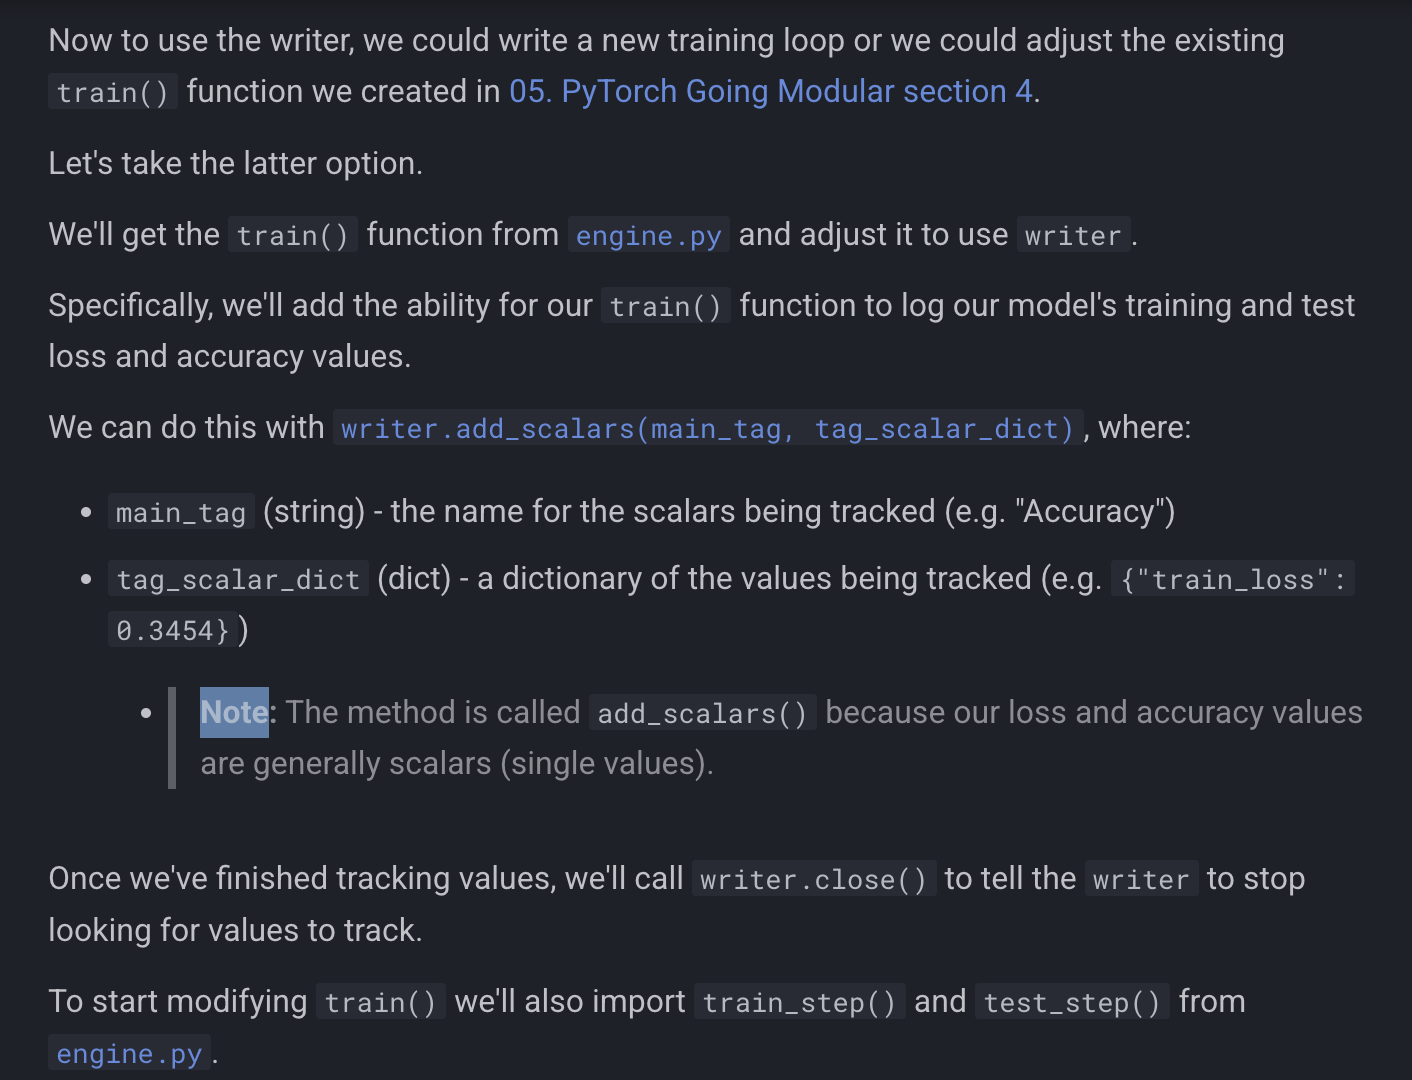

In [ ]:
from typing import Dict , List
from tqdm.auto import tqdm

from going_modular.going_modular.engine import train_step , test_step

def train(model : torch.nn.Module,
          train_dataloader : torch.utils.data.DataLoader,
          test_dataloader : torch.utils.data.DataLoader,
          optimizer : torch.optim.Optimizer,
          loss_fn : torch.nn.Module,
          epochs : int ,
          device : torch.device):

  # create empty results dictionary
  results = {"train_loss" : [],
              "train_acc" : [],
              "test_loss" : [],
              "test_acc" : []
              }

  # loop through training and testing steps for a no. of epocgs
  for epoch in tqdm (range(epochs)) :
    train_loss , train_acc = train_step(model = model ,
                                        dataloader = train_dataloader ,
                                        loss_fn = loss_fn ,
                                        optimizer = optimizer,
                                        device = device)

    test_loss , test_acc = test_step(model = model ,
                                     dataloader = test_dataloader ,
                                     loss_fn = loss_fn ,
                                     device = device)

    # print out what's happening
    print(
        f"Epoch : {epoch+1} | "
        f"train_loss : {train_loss:.4f} | "
        f"train_acc : {train_acc:.2f}% | "
        f"test_loss : {test_loss:.4f} | "
        f"test_acc : {test_acc:.2f}% | "
    )

    # update results dictionary
    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["test_loss"].append(test_loss)
    results["test_acc"].append(test_acc)

    ### new experiment tracking ###
    # add loss results to Summarywriter
    writer.add_scalars(main_tag = "Loss" ,
                       tag_scalar_dict = {"train_loss" : train_loss,
                                          "test_loss" : test_loss},
                       global_step = epoch )
    # add accuracy results to SummaryWriter
    writer.add_scalars(main_tag = "Accuracy",
                       tag_scalar_dict = {"train_acc" : train_acc,
                                         "test_acc" : test_acc},
                       global_step = epoch )

    # track the pytorch model architecture
    writer.add_graph(model = model ,
                     # pass in an exammple input
                     input_to_model = torch.randn(32 ,3 ,224,224).to(device))

  # close the writer
  writer.close()

  ### end new ###
  # return the filled results at the end of the epochs
  return results


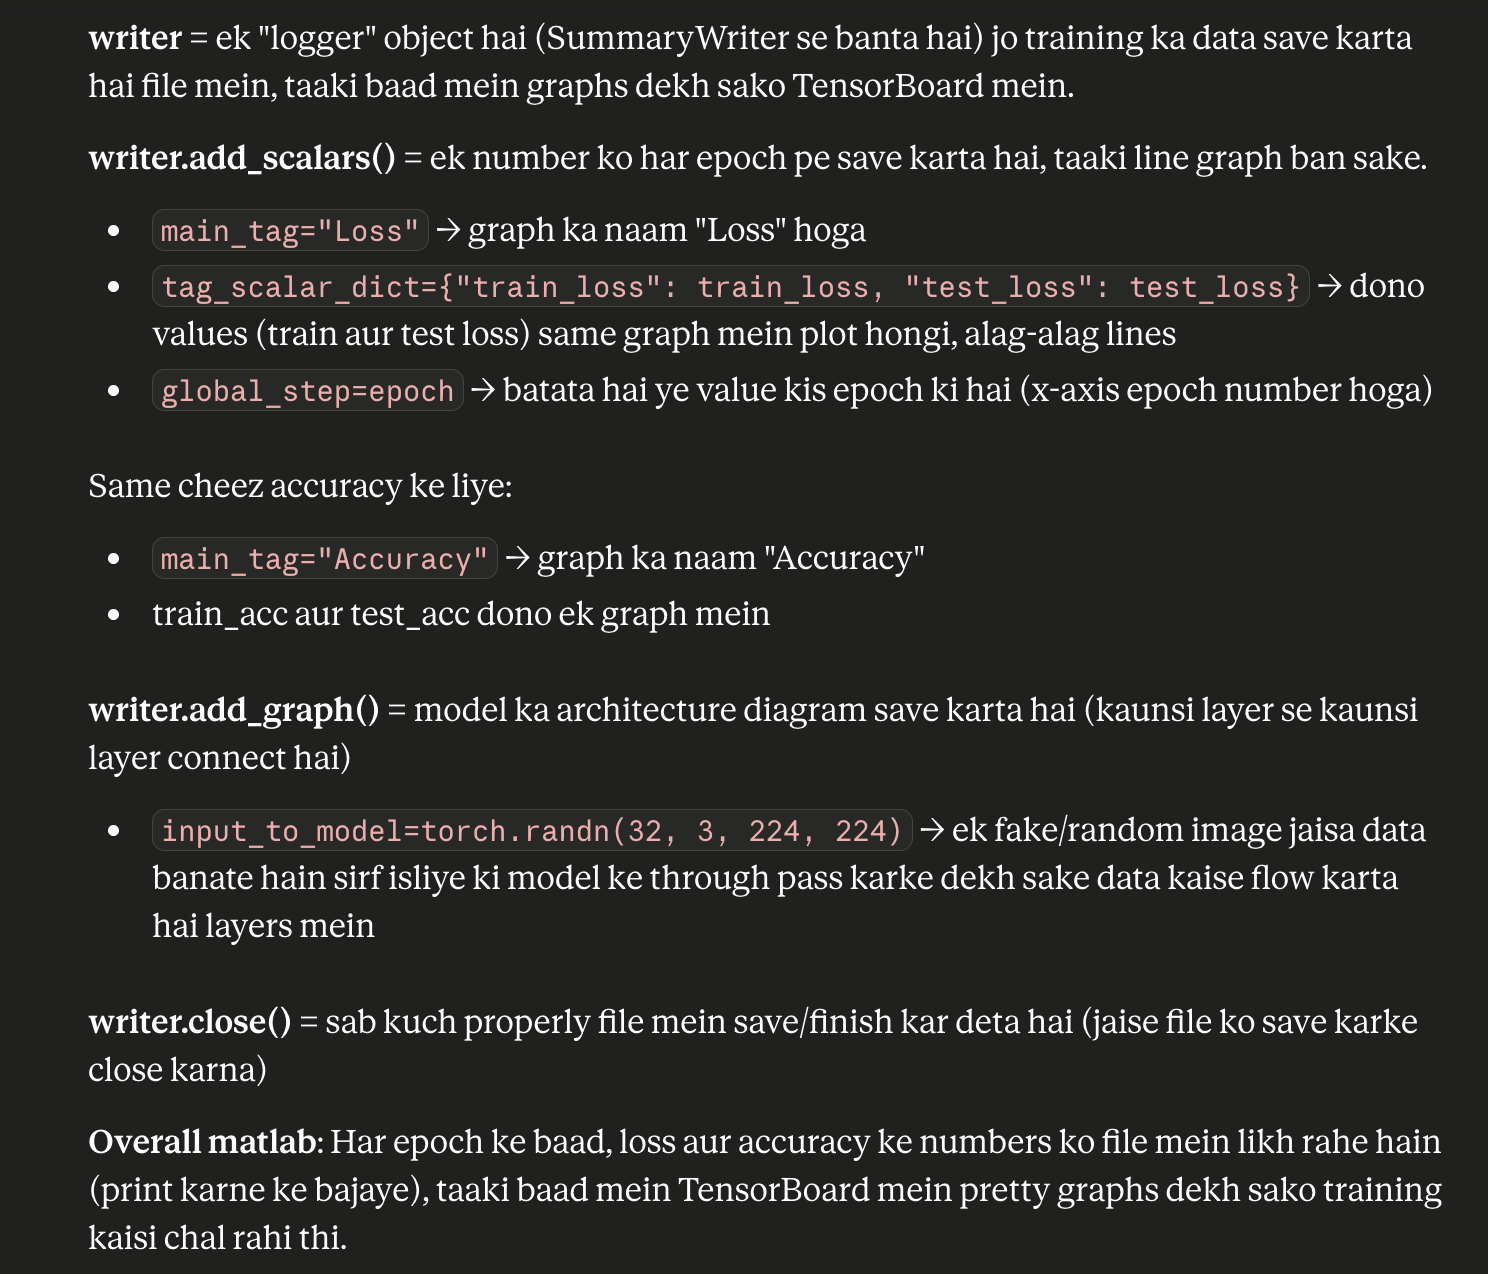

Note : - TensorBoard = ek visualization tool hai jo training metrics (jaise loss, accuracy) ko real-time graphs mein dikhata hai, taaki model ka performance track aur compare kar sako easily.

In [ ]:
"""
Our train() function is now updated to use a SummaryWriter() instance to track our model's results.

How about we try it out for 5 epochs?
"""

# train model
# not using engine.train() since the original scipt isn't updated to use writer

set_seeds()
results = train(model = model ,
                train_dataloader = train_dataloader ,
                test_dataloader = test_dataloader ,
                device = device ,
                loss_fn = loss_fn ,
                optimizer = optimizer ,
                epochs = 2)

  0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch : 1 | train_loss : 1.0883 | train_acc : 0.42% | test_loss : 0.8914 | test_acc : 0.68% | 
Epoch : 2 | train_loss : 0.8937 | train_acc : 0.66% | test_loss : 0.8082 | test_acc : 0.77% | 


In [ ]:
results

{'train_loss': [1.088293395936489, 0.8936692252755165],
 'train_acc': [0.41796875, 0.6640625],
 'test_loss': [0.8914492328961691, 0.8082305788993835],
 'test_acc': [0.6818181818181818, 0.774621212121212]}

# 5. View our model's results in TensorBoard

The SummaryWriter() class stores our model's results in a directory called runs/ in TensorBoard format by default.

TensorBoard is a visualization program created by the TensorFlow team to view and inspect information about models and data.

You know what that means?

It's time to follow the data visualizer's motto and visualize, visualize, visualize!

You can view TensorBoard in a number of ways:

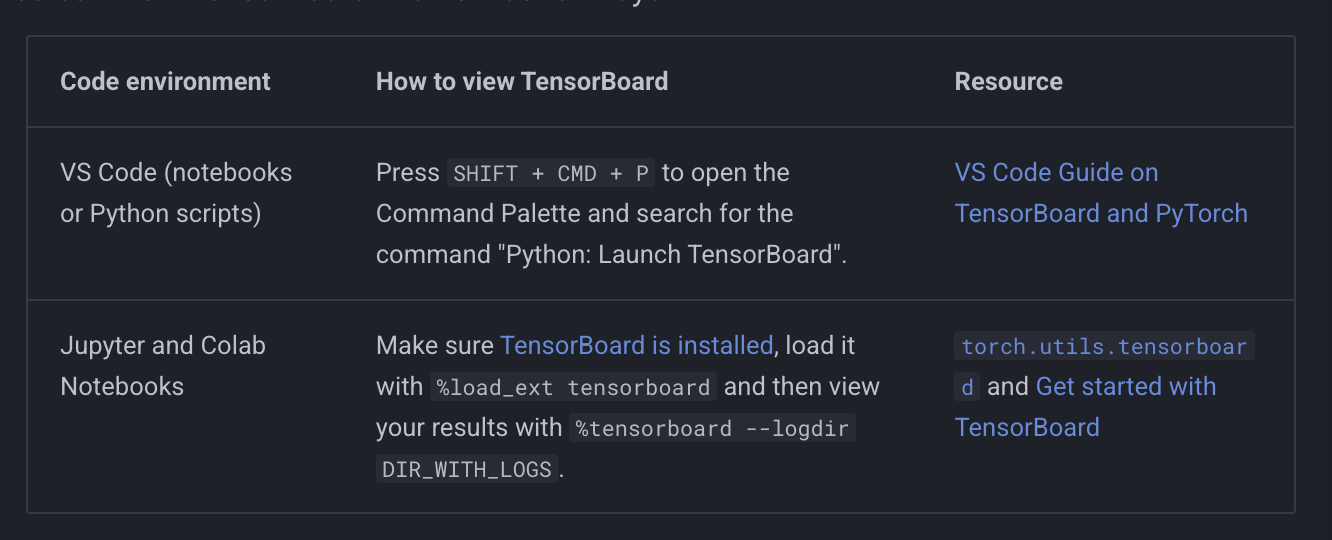

In [ ]:
# Example code to run in Jupyter or Google Colab Notebook (uncomment to try it out)
# %load_ext tensorboard
# %tensorboard --logdir runs

#### check this out -

https://www.tensorflow.org/tensorboard/tensorboard_in_notebooks

# 6. Create a helper function to build SummaryWriter() instances¶
The SummaryWriter() class logs various information to a directory specified by the log_dir parameter.

How about we make a helper function to create a custom directory per experiment?

In essence, each experiment gets its own logs directory.

For example, say we'd like to track things like:

* Experiment date/timestamp - when did the experiment take place?

* Experiment name - is there something we'd like to call the experiment?

* Model name - what model was used?

* Extra - should anything else be tracked?

Let's create a helper function called create_writer() that produces a SummaryWriter() instance tracking to a custom log_dir.

Ideally, we'd like the log_dir to be something like:

runs/YYYY-MM-DD/experiment_name/model_name/extra

Where YYYY-MM-DD is the date the experiment was run (you could add the time if you wanted to as well).

In [ ]:
# just explaination of code
""" Creates a torch.utils.tensorboard.writer.SummaryWriter() instance saving to a specific log_dir.

    log_dir is a combination of runs/timestamp/experiment_name/model_name/extra.

    Where timestamp is the current date in YYYY-MM-DD format.

    Args:
        experiment_name (str): Name of experiment.
        model_name (str): Name of model.
        extra (str, optional): Anything extra to add to the directory. Defaults to None.

    Returns:
        torch.utils.tensorboard.writer.SummaryWriter(): Instance of a writer saving to log_dir.

    Example usage:
        # Create a writer saving to "runs/2022-06-04/data_10_percent/effnetb2/5_epochs/"
        writer = create_writer(experiment_name="data_10_percent",
                               model_name="effnetb2",
                               extra="5_epochs")
        # The above is the same as:
        writer = SummaryWriter(log_dir="runs/2022-06-04/data_10_percent/effnetb2/5_epochs/")
    """
print("explaination")


explaination


In [ ]:
def create_writer(experiment_name : str ,
                  model_name : str ,
                  extra : str = None ):
  from datetime import datetime
  import os

  # get timestamp of current date
  # (all experiments on certain day live in same folder)
  timestamp = datetime.now().strftime("%Y-%m-%d")# returns current date in YYYY-MM-DD format

  if extra :
    # create log directory path
    log_dir = os.path.join("runs" , timestamp , experiment_name , model_name ,extra)
  else :
    log_dir = os.path.join("runs" , timestamp , experiment_name , model_name)

  print(f"[info] created SummaryWriter , saving to. : {log_dir}...")
  return SummaryWriter(log_dir = log_dir)

In [ ]:
# create an example writer
example_writer = create_writer(experiment_name = "data_10_percent",
                               model_name = "effnetb0",
                               extra = "5_epochs")


[info] created SummaryWriter , saving to. : runs/2026-08-03/data_10_percent/effnetb0/5_epochs...


# 6.1 Update the train() function to include a writer parameter
Our create_writer() function works fantastic.

How about we give our train() function the ability to take in a writer parameter so we actively update the SummaryWriter() instance we're using each time we call train().

For example, say we're running a series of experiments, calling train() multiple times for multiple different models, it would be good if each experiment used a different writer.

One writer per experiment = one logs directory per experiment.

To adjust the train() function we'll add a writer parameter to the function and then we'll add some code to see if there's a writer and if so, we'll track our information there.

In [ ]:
from typing import Dict , List
from tqdm.auto import tqdm

# add writer parameter to train()
def train(model : torch.nn.Module,
          train_dataloader : torch.utils.data.DataLoader,
          test_dataloader : torch.utils.data.DataLoader,
          loss_fn : torch.nn.Module ,
          optimizer : torch.optim.Optimizer,
          epochs : int ,
          device : torch.device ,
          writer : torch.utils.tensorboard.writer.SummaryWriter): # new parameter to take in a writer
  # create empty results dictionary
  results = {"train_loss" : [],
             "train_acc" : [],
             "test_loss" : [],
             "test_acc" : []}

  # Loop through training and testing steps for a no. of epochs
  for epoch in tqdm(range(epochs)) :
    train_loss , train_acc = train_step(model = model ,
                                        dataloader = train_dataloader ,
                                        loss_fn = loss_fn,
                                        optimizer = optimizer,
                                        device = device)

    test_loss ,test_acc = test_step(model = model,
                                     dataloader = test_dataloader ,
                                     loss_fn = loss_fn ,
                                     device = device)
    # print out what's happening
    print(
        f"epoch : {epoch+1} |"
        f"train_loss : {train_loss:.4f} | "
        f"train_acc : {train_acc:.2f}% | "
        f"test_loss : {test_loss:.4f} | "
        f"test_acc : {test_acc:.2f}% "
    )

    # update results dictionary
    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["test_acc"].append(test_acc)
    results["test_loss"].append(test_loss)

    ### New: Use the writer parameter to track experiments ###
    # See if there's a writer, if so, log to it

    if writer :
      # add results to SummaryWriter
      writer.add_scalars(main_tag = "Loss",
                         tag_scalar_dict = {"train_loss" : train_loss,
                                            "test_loss" : test_loss},
                         global_step = epoch)
      writer.add_scalars(main_tag = "accuracy",
                         tag_scalar_dict = {"train_acc" : train_acc,
                                            "test_acc": test_acc},
                         global_step = epoch )

      # close the writer
      writer.close()

    else :
      pass

    ### End new ###

    # return the filled results at the end of the epochs

  return results


# 7. Setting up a series of modelling experiments

Previously we've been running various experiments and inspecting the results one by one.

But what if we could run multiple experiments and then inspect the results all together?

### 7.1  What kind of experiments should you run?
That's the million dollar question in machine learning.

Because there's really no limit to the experiments you can run.

Such a freedom is why machine learning is so exciting and terrifying at the same time.

This is where you'll have to put on your scientist coat and remember the machine learning practitioner's motto: experiment, experiment, experiment!

Every hyperparameter stands as a starting point for a different experiment:

* Change the number of epochs.
* Change the number of layers/hidden units.
* Change the amount of data.
* Change the learning rate.
* Try different kinds of data augmentation.
* Choose a different model architecture.

### 7.2 What experiments are we going to run ?
Our goal is to improve the model powering FoodVision Mini without it getting too big.

In essence, our ideal model achieves a high level of test set accuracy (90%+) but doesn't take too long to train/perform inference (make predictions).

We've got plenty of options but how about we keep things simple?

* Let's try a combination of:

1. A different amount of data (10% of Pizza, Steak, Sushi vs. 20%)

2. A different model (torchvision.models.efficientnet_b0 vs. torchvision.models.efficientnet_b2)

3. A different training time (5 epochs vs. 10 epochs)

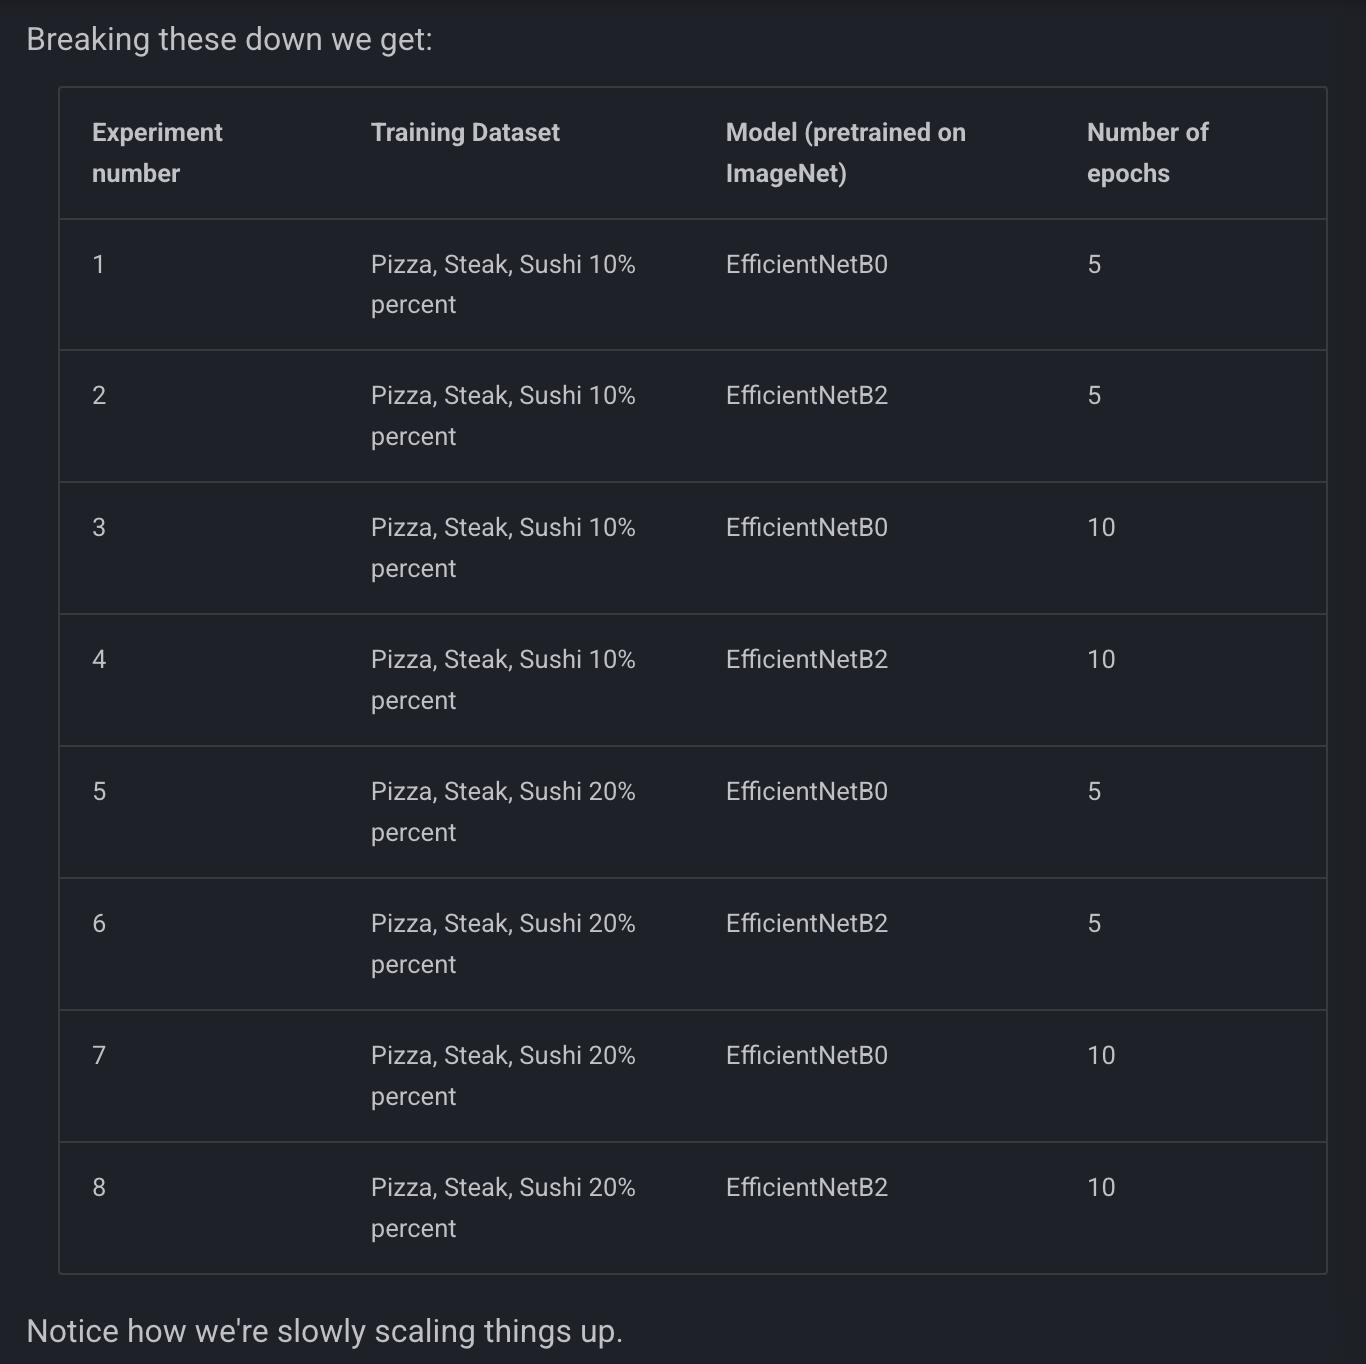

### 7.3 Download different datasets

:- Before we start running our series of experiments, we need to make sure our datasets are ready.

* We'll need two forms of a training set:

1. A training set with 10% of the data of Food101 pizza, steak, sushi images (we've already created this above but we'll do it again for completeness).

2. A training set with 20% of the data of Food101 pizza, steak, sushi images.
For consistency, all experiments will use the same testing dataset (the one from the 10% data split).

* Both datasets are available from the course GitHub:

1. Pizza, steak, sushi 10% training data.

. Pizza, steak, sushi 20% training data.

In [ ]:
# download 10 percent and 20 percent training data

data_10_percent_path = download_data(source = "https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                                     destination = "pizza_steak_sushi")

data_20_percent_path = download_data(source = "https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip",
                                     destination = "pizza_steak_sushi_20_percent")

[INFO] data/pizza_steak_sushi directory exists, skipping download.
[INFO] Did not find data/pizza_steak_sushi_20_percent directory, creating one...
[INFO] Downloading pizza_steak_sushi_20_percent.zip from https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip...
[INFO] Unzipping pizza_steak_sushi_20_percent.zip data...


In [ ]:
# data downloaded

In [ ]:
# setup training directory paths
train_dir_10_percent = data_10_percent_path / "train"
train_dir_20_percent = data_20_percent_path / "train"

# setup testing directory paths (note: use the same testdatset for both )
test_dir = data_10_percent_path / "test"

# check the directories
print(f"training directory 10%  : {train_dir_10_percent}")
print(f"training directory 20% : {train_dir_20_percent}")
print(f"testing directory : {test_dir}")

training directory 10%  : data/pizza_steak_sushi/train
training directory 20% : data/pizza_steak_sushi_20_percent/train
testing directory : data/pizza_steak_sushi/test


### 7.4 Transform Datasets and create DataLoaders
Next we'll create a series of transforms to prepare our images for our model(s).

To keep things consistent, we'll manually create a transform (just like we did above) and use the same transform across all of the datasets.

The transform will:

1. Resize all the images (we'll start with 224, 224 but this could be changed).

2. Turn them into tensors with values between 0 & 1.

3. Normalize them in way so their distributions are inline with the ImageNet dataset (we do this because our models from torchvision.models have been pretrained on ImageNet).

In [ ]:
from torchvision import transforms

# create a transform to normalize data distribution to be inline with ImageNet
normalize = transforms.Normalize(mean = [0.485 , 0.456, 0.4046],
                                 std = [0.229 , 0.224 , 0.225])

# Compose transforms into a pipeline
simple_transform = transforms.Compose([
    transforms.Resize((224, 224)), # 1. Resize the images
    transforms.ToTensor(), # 2. Turn the images into tensors with values between 0 & 1
    normalize # 3. Normalize the images so their distributions match the ImageNet dataset
])

Now let's create our DataLoaders using the create_dataloaders() function from data_setup.py we created in 05. PyTorch Going Modular section 2.

We'll create the DataLoaders with a batch size of 32.

For all of our experiments we'll be using the same test_dataloader (to keep comparisons consistent).

In [ ]:
BATCH_SIZE = 32

# Create 10% training and test DataLoaders
train_dataloader_10_percent, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir_10_percent,
    test_dir=test_dir,
    transform=simple_transform,
    batch_size=BATCH_SIZE
)

# Create 20% training and test data DataLoders
train_dataloader_20_percent, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir_20_percent,
    test_dir=test_dir,
    transform=simple_transform,
    batch_size=BATCH_SIZE
)

# Find the number of samples/batches per dataloader (using the same test_dataloader for both experiments)
print(f"Number of batches of size {BATCH_SIZE} in 10 percent training data: {len(train_dataloader_10_percent)}")
print(f"Number of batches of size {BATCH_SIZE} in 20 percent training data: {len(train_dataloader_20_percent)}")
print(f"Number of batches of size {BATCH_SIZE} in testing data: {len(test_dataloader)} (all experiments will use the same test set)")
print(f"Number of classes: {len(class_names)}, class names: {class_names}")

Number of batches of size 32 in 10 percent training data: 8
Number of batches of size 32 in 20 percent training data: 15
Number of batches of size 32 in testing data: 3 (all experiments will use the same test set)
Number of classes: 3, class names: ['pizza', 'steak', 'sushi']


### 7.5 Create feature extractor models
Time to start building our models.

We're going to create two feature extractor models:

torchvision.models.efficientnet_b0() pretrained backbone + custom classifier head (EffNetB0 for short).
torchvision.models.efficientnet_b2() pretrained backbone + custom classifier head (EffNetB2 for short).
To do this, we'll freeze the base layers (the feature layers) and update the model's classifier heads (output layers) to suit our problem just like we did in 06. PyTorch Transfer Learning section 3.4.

We saw in the previous chapter the in_features parameter to the classifier head of EffNetB0 is 1280 (the backbone turns the input image into a feature vector of size 1280).

Since EffNetB2 has a different number of layers and parameters, we'll need to adapt it accordingly.

In [ ]:
import torchvision
from torchinfo import summary

# 1. create an instance of EffNetB2 with pretrained weights
effnetb2_weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT # "DEFAULT" means best available weights
effnetb2 = torchvision.models.efficientnet_b2(weights = effnetb2_weights)


# # 2. get a summary of standard EffNetB2 from torchvision.models(uncomment for full output)
summary(model = effnetb2,
        input_size = (32,3, 224,224),
        col_names = ["input_size" , "output_size" , "num_params" , "trainable"],
        col_width = 20,
        row_settings = ["var_names"])

Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 179MB/s]


Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 1000]           --                   True
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1408, 7, 7]     --                   True
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   True
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   864                  True
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   64                   True
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 16, 112

In [ ]:
#3 . Get the number of in_features of the EfficientNetB2 classifier layer

print(f"Number of in_features to final layer of EfficientNEtB2 : {len(effnetb2.classifier.state_dict()['1.weight'][0])}")


Number of in_features to final layer of EfficientNEtB2 : 1408


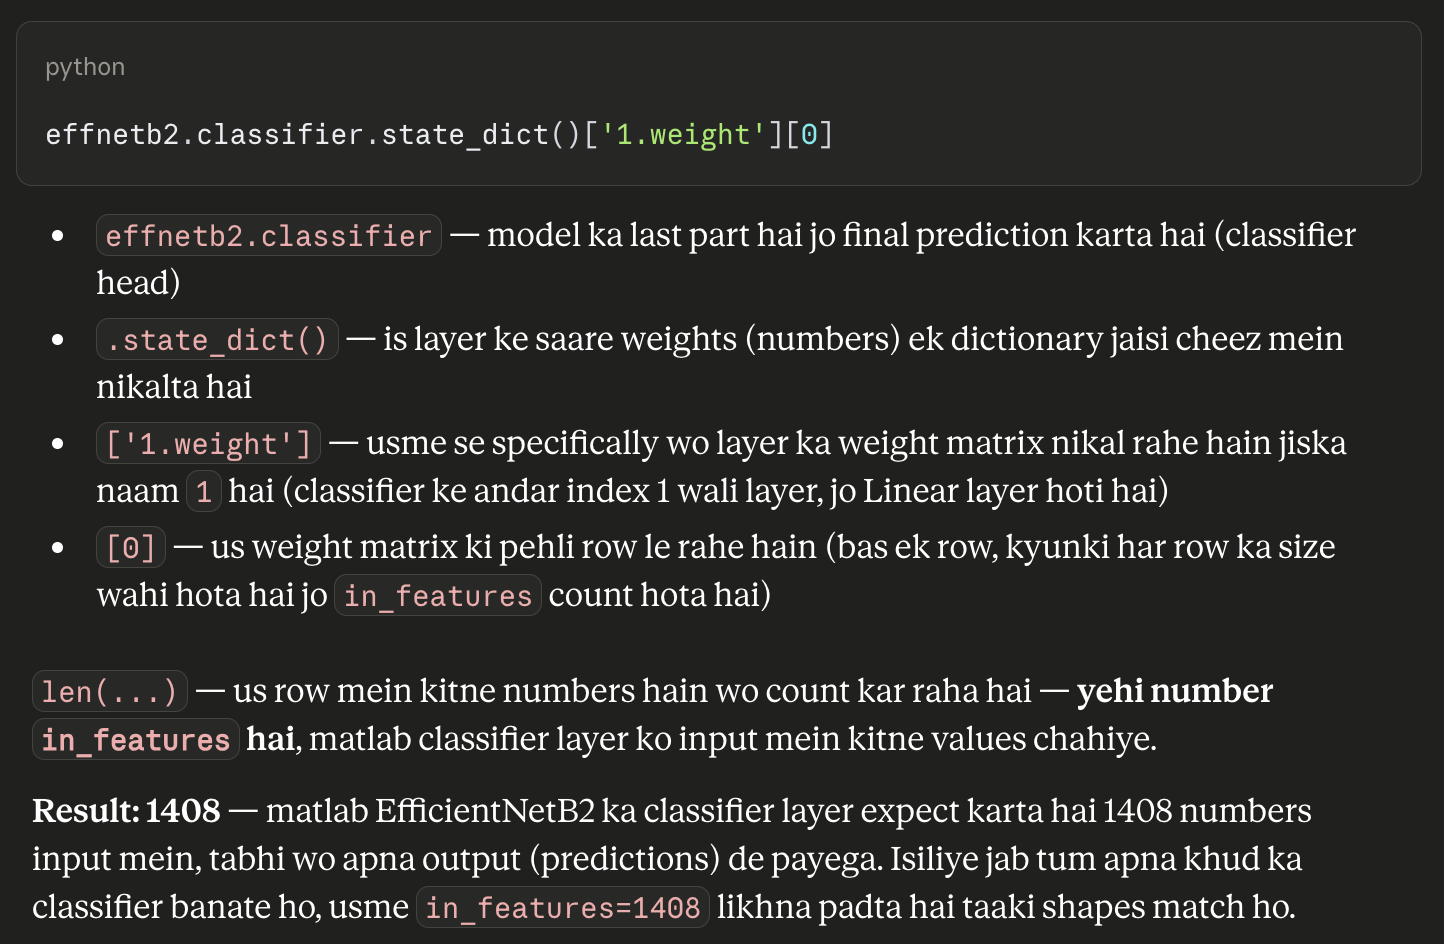

1. Now we know the required number of in_features for the EffNetB2 model, let's create a couple of helper functions to setup our EffNetB0 and EffNetB2 feature extractor models.

We want these functions to:

* Get the base model from torchvision.models

* Freeze the base layers in the model (set requires_grad=False)

* Set the random seeds (we don't need to do this but since we're running a series of experiments and initalizing a new layer with random weights, we want the randomness to be similar for each experiment)

* Change the classifier head (to suit our problem)

* Give the model a name (e.g. "effnetb0" for EffNetB0)

In [ ]:
import torchvision
from torch import nn

# get num out fetures (one for each class pizza , steak , sushi)
OUT_FEATURES = len(class_names)

# create an EffnetB0 feature extractor
def create_effnetb0():
  # 1. Get the base model with pretrained weights and send to target device
  weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
  model = torchvision.models.efficientnet_b0(weights = weights).to(device)

  # 2. Freeze the base model layers
  for param in model.features.parameters():
    param.requires_grad = False

  # 3. set the seeds
  set_seeds()

  # 4. change the classifier head
  model.classifier = nn.Sequential(
      nn.Dropout(p = 0.2),
      nn.Linear(in_features = 1280 , out_features = OUT_FEATURES)
  ).to(device)

  # 5. Give the model a name
  model.name = "effnetb0"
  print(f"[INFO] created new {model.name} model. ")
  return model

# create an EffNetB2 feature extractor
def create_effnetb2():
  # 1. Get the base model with pretrained weights and send to target device

  weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT
  model = torchvision.models.efficientnet_b2(weights = weights).to(device)

  # freeze the base model layers
  for param in model.features.parameters():
    param.requires_grad = True

  # set the seed
  set_seeds()

  # change the classifier head
  model.classifier = nn.Sequential(
      nn.Dropout(p = 0.3),
      nn.Linear(in_features = 1408 , out_features = OUT_FEATURES)
  ).to(device)

  # 5. give the model a name
  model.name = "effnetb2"
  print(f"[info] created new. {model.name} model. ")
  return model

In [ ]:
# .name - ye ek attribute hain
# (specificially instance attribute ).

In [ ]:
effnetb0 = create_effnetb0()

[INFO] created new effnetb0 model. 


In [ ]:
# Get an output summary of the layers in our EffNetB0 feature extractor model (uncomment to view full output)

summary(model = effnetb0,
        input_size = (32, 3 ,224, 224),
        col_names = ["input_size", "output_size" , "num_params" , "trainable"],
        col_width = 20 ,
        row_settings = ["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [ ]:
effnetb2 = create_effnetb2()

[info] created new. effnetb2 model. 


In [ ]:
summary(model = effnetb2,
        input_size = (32 ,3, 224, 224),
        col_names = ["input_size" , "output_size" , "num_params" , "trainable"],
        col_width = 20 ,
        row_settings = ["var_names"])


Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   True
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1408, 7, 7]     --                   True
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   True
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   864                  True
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   64                   True
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 16, 112

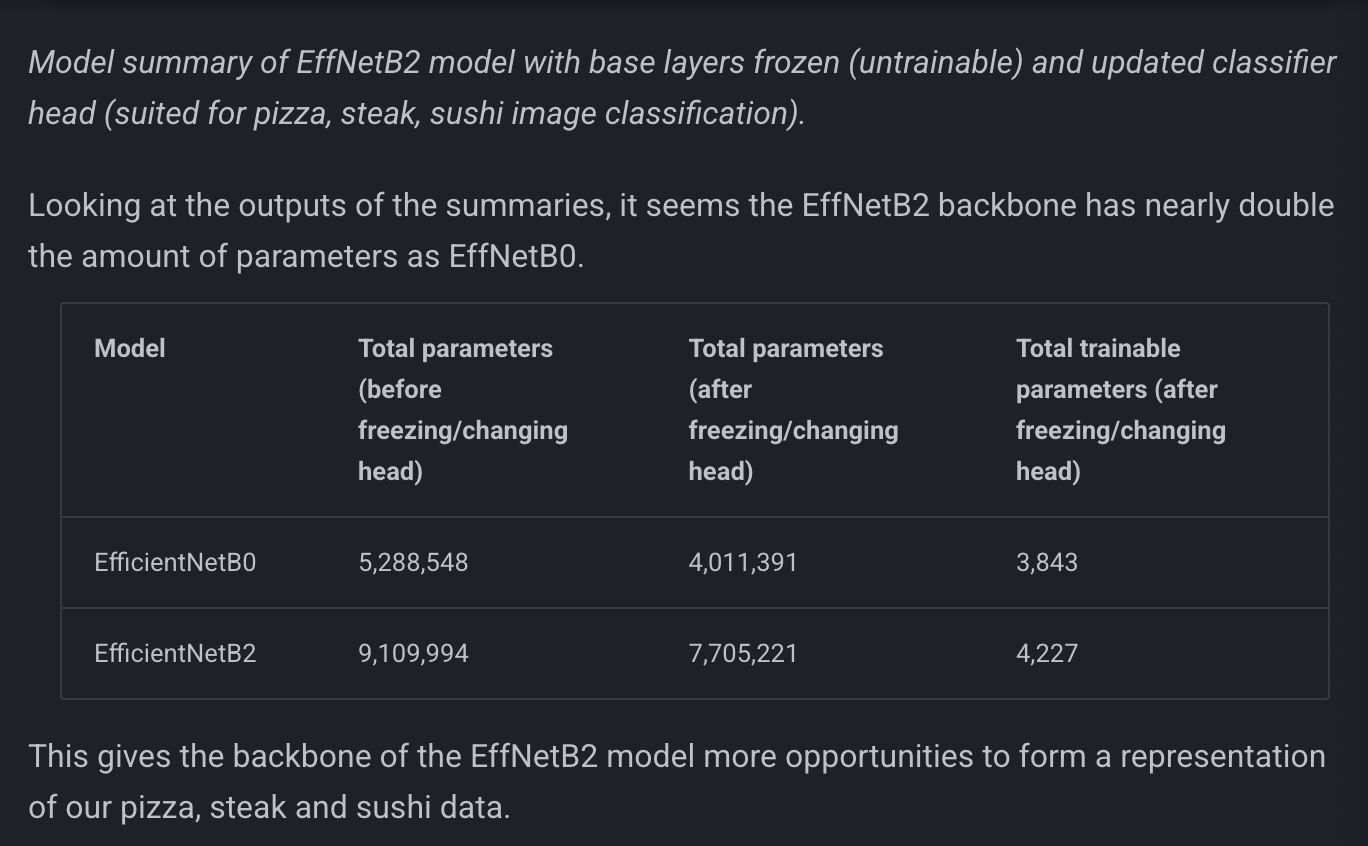

### 7.6 Create experiments and set up training code
We've prepared our data and prepared our models, the time has come to setup some experiments!

We'll start by creating two lists and a dictionary:

1. A list of the number of epochs we'd like to test ([5, 10])

2. A list of the models we'd like to test (["effnetb0", "effnetb2"])

3. A dictionary of the different training DataLoaders

In [ ]:
# 1. Create epochs list
num_epochs = [5, 10]

# 2. create models list(need to create a new model for each experiment)
models = ["effnetb0" , "effnetb2"]

# 3. create dataloaders dictionary for various dataloaders
train_dataloaders = {"data_10_percent" : train_dataloader_10_percent ,
                     "data_20_percent" : train_dataloader_20_percent }

We'll also save the model at the end of each experiment so later on we can load back in the best model and use it for making predictions.

Specifically, let's go through the following steps:

1. Set the random seeds (so our experiment results are reproducible, in practice, you might run the same experiment across ~3 different seeds and average the results).

2. Keep track of different experiment numbers (this is mostly for pretty print outs).

3. Loop through the train_dataloaders dictionary items for each of the different training DataLoaders.

4. Loop through the list of epoch numbers.

5. Loop through the list of different model names.

6. Create information print outs for the current running experiment (so we know what's happening).

7. Check which model is the target model and create a new EffNetB0 or EffNetB2 instance (we create a new model instance each experiment so all models start from the same standpoint).

8. Create a new loss function (torch.nn.CrossEntropyLoss()) and optimizer (torch.optim.Adam(params=model.parameters(), lr=0.001)) for each new experiment.

9. Train the model with the modified train() function passing the appropriate details to the writer parameter.

10. Save the trained model with an appropriate file name to file with save_model() from utils.py.

In [ ]:
%%time
from going_modular.going_modular.utils import save_model

# 1. set the random seeds
set_seeds(seed = 42)

# 2. keep the track of experiment numbers
experiment_number = 0

# 3. Loop through each DataLoader
for dataloader_name ,train_dataloader in train_dataloaders.items():

  # 4. loop through each number of epochs
  for epochs in num_epochs :

    # 5. loop through each model name and create a new model based on the name
    for model_name in models :

      # 6. create information print outs
      experiment_number += 1
      print(f"[INFO] EXPERIMENT number  : {experiment_number}")
      print(f"[INFO] Model : {model_name}")
      print(f"[INFO] DataLoader : {dataloader_name}")
      print(f"[INFO] Number of epochs : {epochs}")

      # 7. select the model
      if model_name  == "effnetb0":
        model = create_effnetb0() # creates a new model each time (important because we want each experiment to start from scratch)
      else :
        model = create_effnetb2() # creates a new model each time (important because we want each experiment to start from scratch)

      # 8. Create a new loss and optimizer for every model
      loss_fn = nn.CrossEntropyLoss()
      optimizer = torch.optim.Adam(params = model.parameters() , lr = 0.001)

      # 9. Train target model with target dataloaders and track experiments
      train(model = model ,
            train_dataloader = train_dataloader,
            test_dataloader = test_dataloader,
            optimizer = optimizer ,
            loss_fn = loss_fn ,
            device = device ,
            epochs = epochs ,
            writer = create_writer(experiment_name = dataloader_name ,
                                   model_name = model_name ,
                                   extra = f"{epochs}_epochs"))

      # 10 . Save the model to file so we can get back the best model
      save_filepath = f"07_{model_name}_{dataloader_name}_{epochs}_epochs.pth"
      save_model(model = model ,
                 target_dir = "models",
                 model_name = save_filepath)
      print("_"*50 + "\n")



[INFO] EXPERIMENT number  : 1
[INFO] Model : effnetb0
[INFO] DataLoader : data_10_percent
[INFO] Number of epochs : 5
[INFO] created new effnetb0 model. 
[info] created SummaryWriter , saving to. : runs/2026-08-03/data_10_percent/effnetb0/5_epochs...


  0%|          | 0/5 [00:00<?, ?it/s]

epoch : 1 |train_loss : 1.0497 | train_acc : 0.45% | test_loss : 0.9296 | test_acc : 0.45% 
epoch : 2 |train_loss : 0.9335 | train_acc : 0.52% | test_loss : 0.8193 | test_acc : 0.64% 
epoch : 3 |train_loss : 0.7878 | train_acc : 0.73% | test_loss : 0.6944 | test_acc : 0.89% 
epoch : 4 |train_loss : 0.6920 | train_acc : 0.88% | test_loss : 0.6497 | test_acc : 0.90% 
epoch : 5 |train_loss : 0.6931 | train_acc : 0.74% | test_loss : 0.6419 | test_acc : 0.84% 
[INFO] Saving model to: models/07_effnetb0_data_10_percent_5_epochs.pth
__________________________________________________

[INFO] EXPERIMENT number  : 2
[INFO] Model : effnetb2
[INFO] DataLoader : data_10_percent
[INFO] Number of epochs : 5
[info] created new. effnetb2 model. 
[info] created SummaryWriter , saving to. : runs/2026-08-03/data_10_percent/effnetb2/5_epochs...


  0%|          | 0/5 [00:00<?, ?it/s]

epoch : 1 |train_loss : 0.7019 | train_acc : 0.65% | test_loss : 0.5256 | test_acc : 0.86% 
epoch : 2 |train_loss : 0.2750 | train_acc : 0.86% | test_loss : 0.5532 | test_acc : 0.88% 


KeyboardInterrupt: 

# 8. View experiments in TensorBoard¶
Training eight models in one go?

check out the results in TensorBoard?

In [ ]:
# viewing tensorboard in jupyter and google colab notebooks (uncomment to view full tensorBoard instances)
%load_ext tensorboard
%tensorboard --logdir runs

Launching TensorBoard...

KeyboardInterrupt: 

# 9. load the best model and make predictions with it


Looking at the TensorBoard logs for our eight experiments, it seems experiment number eight achieved the best overall results (highest test accuracy, second lowest test loss).

This is the experiment that used:

* EffNetB2 (double the parameters of EffNetB0)

* 20% pizza, steak, sushi training data (double the original training data)

* 10 epochs (double the original training time)

In [ ]:
# setup the best model filepath
best_model_path = "model/07_effnetb2_data_20_percent_10_epochs.pth"

# instantiate the new instance of the EffNetB2 (to load the saved state_dict() to)
best_model = create_effnetb2()

# laod the saved best model state_dict()
best_model.load_dict(torch.load(best_model_path))

In [ ]:
# Check the model file size
from pathlib import Path

# Get the model size in bytes then convert to megabytes
effnetb2_model_size = Path(best_model_path).stat().st_size // (1024*1024)
print(f"EfficientNetB2 feature extractor model size: {effnetb2_model_size} MB")



Looks like our best model so far is 29 MB in size. We'll keep this in mind if we want to deploy it later on.

Time to make and visualize some predictions.

We created a pred_and_plot_image() function to use a trained model to make predictions on an image in 06. PyTorch Transfer Learning section 6.

And we can reuse this function by importing it from going_modular.going_modular.predictions.py (I put the pred_and_plot_image() function in a script so we could reuse it).

So to make predictions on various images the model hasn't seen before, we'll first get a list of all the image filepaths from the 20% pizza, steak, sushi testing dataset and then we'll randomly select a subset of these filepaths to pass to our pred_and_plot_image() function.

In [ ]:
# Import function to make predictions on images and plot them
# See the function previously created in section: https://www.learnpytorch.io/06_pytorch_transfer_learning/#6-make-predictions-on-images-from-the-test-set
from going_modular.going_modular.predictions import pred_and_plot_image

# Get a random list of 3 images from 20% test set
import random
num_images_to_plot = 3
test_image_path_list = list(Path(data_20_percent_path / "test").glob("*/*.jpg")) # get all test image paths from 20% dataset
test_image_path_sample = random.sample(population=test_image_path_list,
                                       k=num_images_to_plot) # randomly select k number of images

# Iterate through random test image paths, make predictions on them and plot them
for image_path in test_image_path_sample:
    pred_and_plot_image(model=best_model,
                        image_path=image_path,
                        class_names=class_names,
                        image_size=(224, 224))

### 9.1 Predict on a custom image with the best model
Making predictions on the test dataset is cool but the real magic of machine learning is making predictions on custom images of your own.

So let's import the trusty pizza dad image (a photo of my dad in front of a pizza) we've been using for the past couple of sections and see how our model performs on it.

In [ ]:
# Download custom image
import requests

# Setup custom image path
custom_image_path = Path("data/04-pizza-dad.jpeg")

# Download the image if it doesn't already exist
if not custom_image_path.is_file():
    with open(custom_image_path, "wb") as f:
        # When downloading from GitHub, need to use the "raw" file link
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
        print(f"Downloading {custom_image_path}...")
        f.write(request.content)
else:
    print(f"{custom_image_path} already exists, skipping download.")

# Predict on custom image
pred_and_plot_image(model=model,
                    image_path=custom_image_path,
                    class_names=class_names)